# Steady-state CDR flux

Every GCAM region in `exe_central1p5`, `cec_factor` 1.

In [2]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

S3_RUN = ("s3://carbonplan-carbon-removal/ew-workflows-data/scepter/postprocessed/gcam/"
          "gcam_opr_full2_cec1/exe_central1p5_001_multiSchedule/exe_central1p5")
RCO2    = 0.3   # t CO2 per t rock
DUSTRAD = 0.2   # um

SAVE_ON  = True
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
savehere = REPO / "figures/supp/panels"
savehere.mkdir(parents=True, exist_ok=True)

FS_LABEL, FS_TICK, FS_LEGEND, FS_TITLE, FS_PANEL = 19, 17, 16, 20, 24


def _style(ax, letter, title, xlabel, ylabel):
    ax.set_xlabel(xlabel, fontsize=FS_LABEL)
    ax.set_ylabel(ylabel, fontsize=FS_LABEL)
    ax.set_title(title, fontsize=FS_TITLE, loc="left", pad=18)
    ax.annotate(letter, (0, 1), xycoords="axes fraction", textcoords="offset points",
                xytext=(-14, 18), ha="right", va="baseline", fontsize=FS_PANEL,
                fontweight="bold")
    ax.tick_params(labelsize=FS_TICK)
    ax.spines[["top", "right"]].set_visible(False)

## CDR efficiency vs. CDR flux and rock application flux


In [3]:
VARS = ["cdr_adv_region", "M_D_region", "catbudget_gbas_region", "catbudget_adv_region",
        "catbudget_tflx_region", "catbudget_sic_region"]
ds = (xr.open_zarr(os.path.join(S3_RUN, "ds_cdr_globalScaling_constApp_SUM.zarr"))[VARS]
      .sel(cec_factor=1.0, dustrad=DUSTRAD).sum("time").load())

rate = ds.apprate_base
pot  = RCO2 * ds["M_D_region"]   # rock CO2 potential

eff_reg  = (ds["cdr_adv_region"] / pot).transpose("apprate_base", "site")
eff_glob = ds["cdr_adv_region"].sum("site") / pot.sum("site")
fate     = {k: sign * ds[f"catbudget_{k}_region"].sum("site") / pot.sum("site")
            for k, sign in [("gbas", 1), ("adv", -1), ("tflx", -1), ("sic", -1)]}
a_star   = eff_reg.idxmax("apprate_base")
eff_star = eff_reg.max("apprate_base")

# CDR flux = cumulative CDR / applied ha-yr = rate * RCO2 * efficiency
flux_reg  = RCO2 * rate * eff_reg
flux_glob = RCO2 * rate * eff_glob
flux_star = RCO2 * a_star * eff_star


def plot_fig(x_reg, x_glob, x_star, xname, xlabel, fname, xticks=None):
    fig, (ax_e, ax_f) = plt.subplots(1, 2, figsize=(14, 8), dpi=150, constrained_layout=True)

    ax_e.plot(x_reg, eff_reg, color="#c4c4c4", lw=1.2)[0].set_label("Individual regions")
    ax_e.plot(x_glob, eff_glob, color="#333333", lw=3, label="All regions (GCAM-rock-weighted)")
    ax_e.plot(x_star, eff_star, ls="none", marker="o", ms=9, mfc="#0072B2", mec="white", mew=1.2,
              label="Regional optimum a*")

    ax_f.plot(x_glob, fate["gbas"], color="#333333", lw=2.5, ls="--",
              label="Released by dissolution")
    for k, color, label in [("adv",  "#0072B2", "Exported (CDR)"),
                            ("tflx", "#D55E00", "Retained in soil (CEC buffer)"),
                            ("sic",  "#009E73", "Secondary carbonate (SIC)")]:
        ax_f.plot(x_glob, fate[k], color=color, lw=3, marker="o", ms=8, mec="white", mew=1,
                  label=label)

    for ax, letter, ylabel, title in [
            (ax_e, "a", "CDR efficiency", f"CDR efficiency by {xname}"),
            (ax_f, "b", "Fraction of cation-based\nCDR potential", "Fate of the rock's cations")]:
        ax.set_xscale("log")
        ax.set_xlim(float(x_glob.min()) / 1.4, float(x_glob.max()) * 1.4)
        ax.set_ylim(0, 1)
        if xticks is not None:
            ax.set_xticks(xticks)
            ax.minorticks_off()
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
        _style(ax, letter, title, xlabel, ylabel)
        ax.legend(fontsize=FS_LEGEND, frameon=False, loc="upper center",
                  bbox_to_anchor=(0.5, -0.15), handlelength=2.2)

    plt.show()
    if SAVE_ON:
        fig.savefig(os.path.join(savehere, fname), dpi=300, bbox_inches="tight")

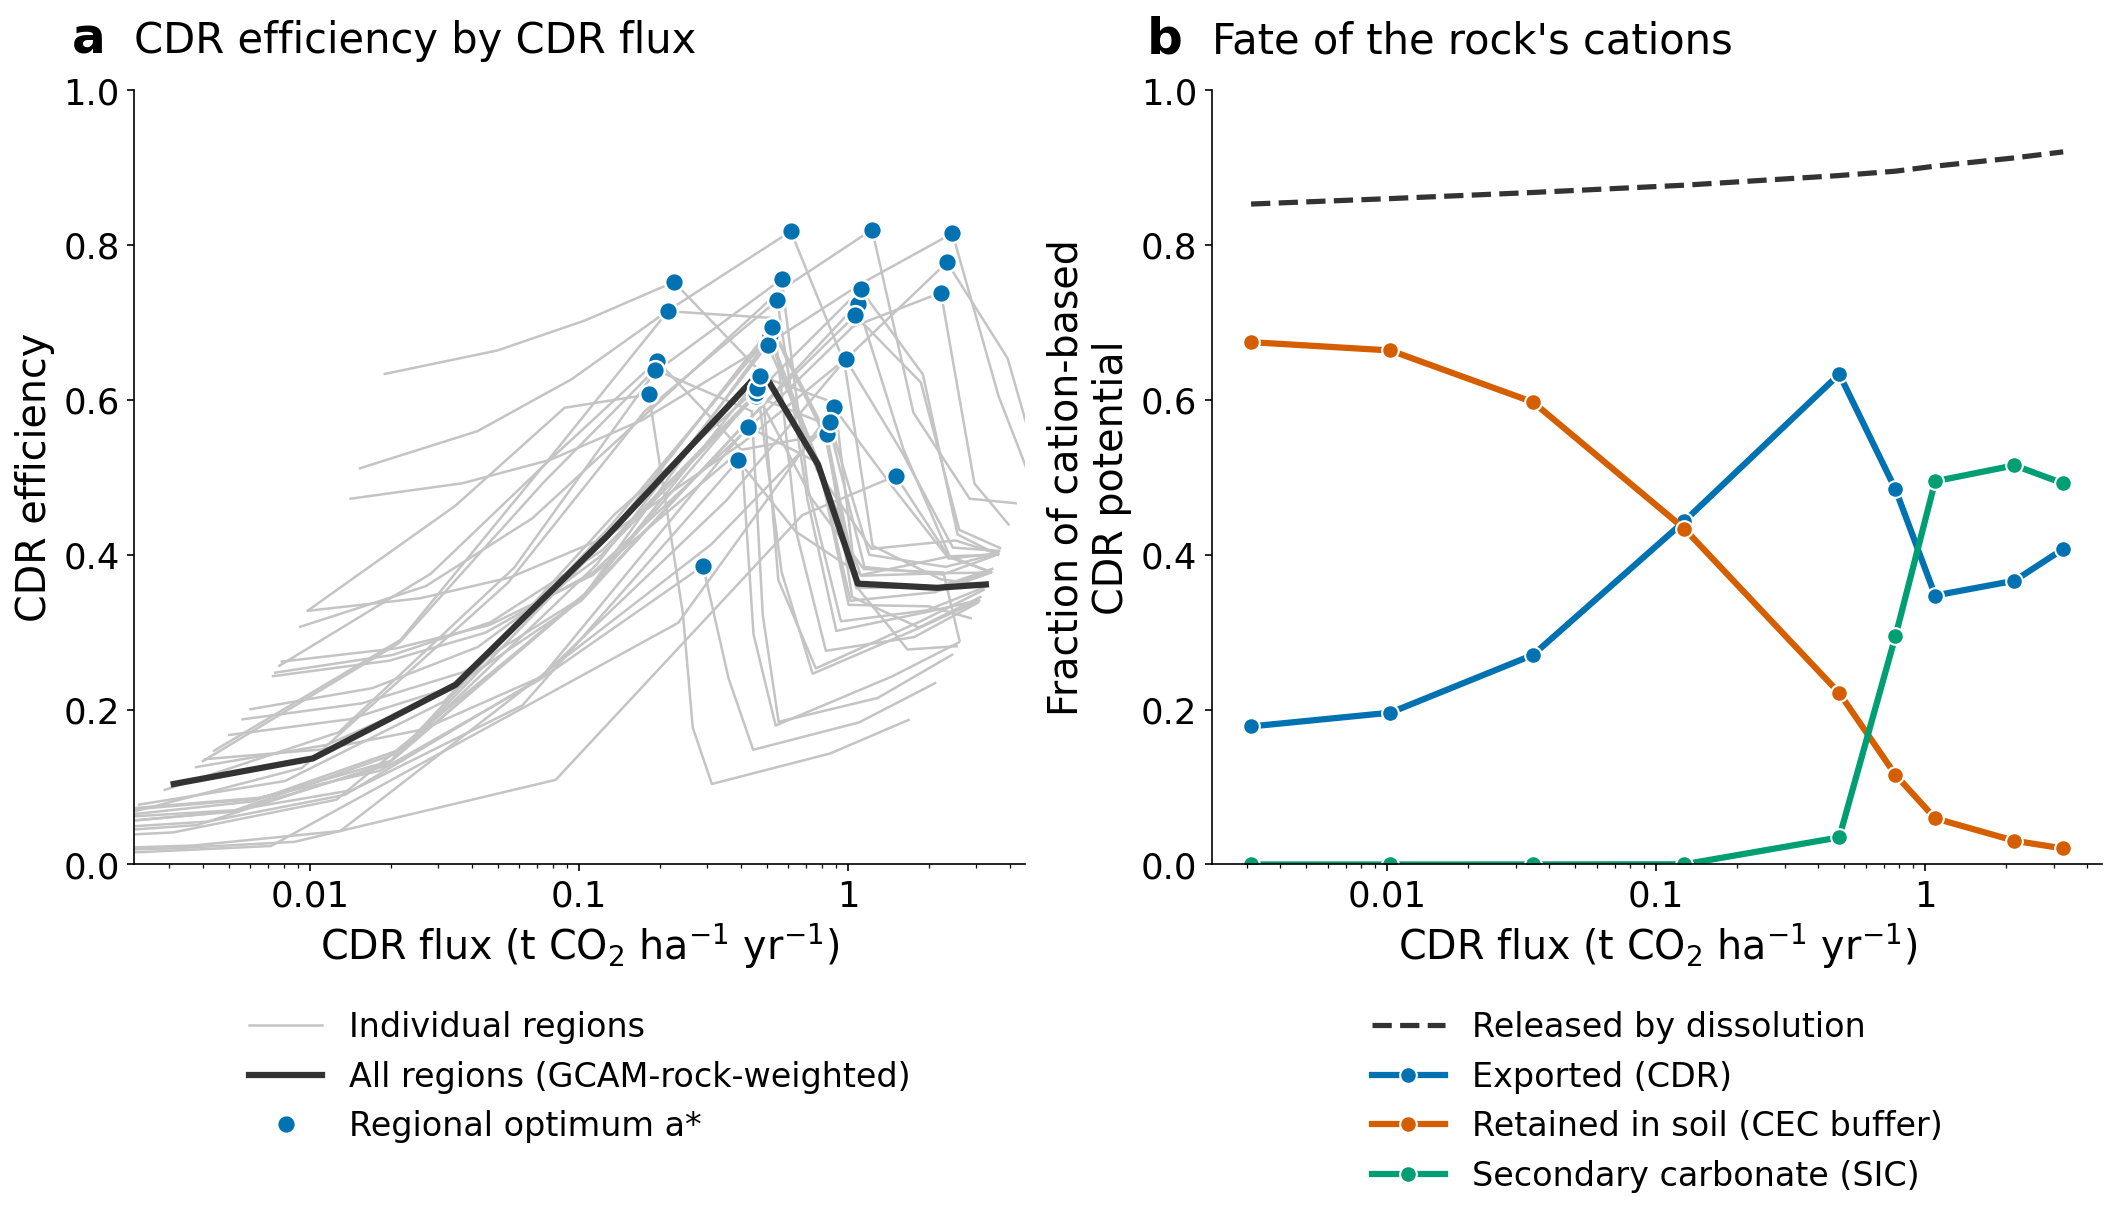

In [7]:
plot_fig(flux_reg, flux_glob, flux_star, "CDR flux", "CDR flux (t CO$_2$ ha$^{-1}$ yr$^{-1}$)",
         "steady-state-cdr-flux.png")

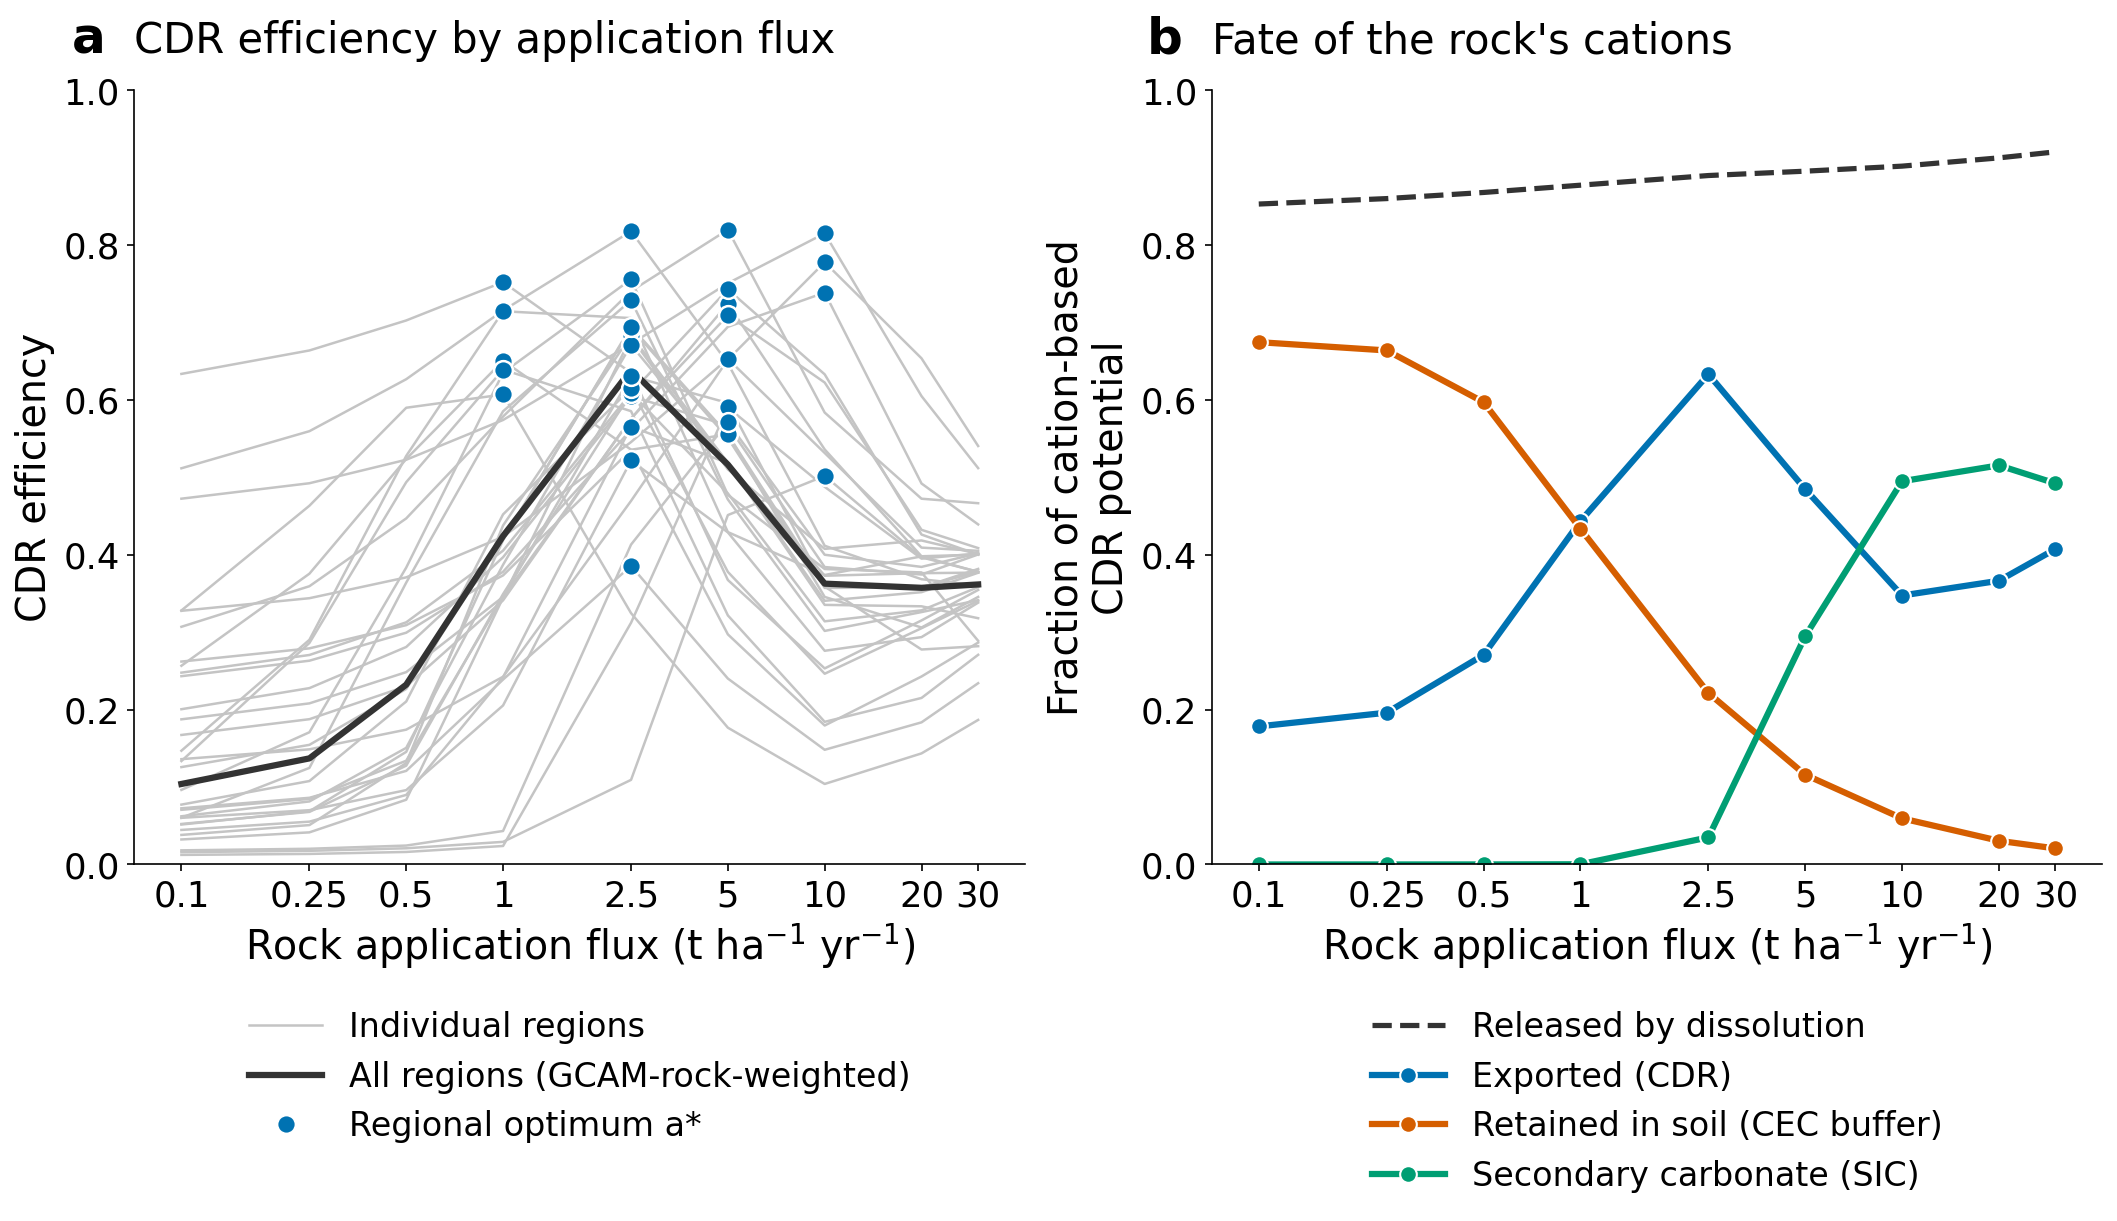

In [8]:
plot_fig(rate, rate, a_star, "application flux", "Rock application flux (t ha$^{-1}$ yr$^{-1}$)",
         "steady-state-app-flux.png", xticks=rate.values)

## Global CDR vs. cropland fraction

Each region spreads at its highest-efficiency rate (a*) on a fraction f of its cropland: its
GCAM-timed run scaled so its peak `cropfrac_ERW` = f. Global CDR is therefore linear in f.

In [7]:
CROPFRACS = np.linspace(0.1, 1, 10)
DUSTRADS  = [0.2, 10.0]   # um, one panel each
ROUGHNESS = {0.2: 50., 10.0: 10.}   # roughness factor per dustrad, for the panel titles
F_MARK    = 0.5          # cropland fraction read off with gray guides

dt = (xr.open_zarr(os.path.join(S3_RUN, "ds_cdr_globalScaling_constApp_SUM.zarr"))
      [["cdr_adv_region", "M_D_region", "cropfrac_ERW"]]
      .sel(cec_factor=1.0, dustrad=DUSTRADS).load())
eff  = dt["cdr_adv_region"].sum("time") / (RCO2 * dt["M_D_region"].sum("time"))
opt  = dt.sel(apprate_base=eff.idxmax("apprate_base"))   # every region at its a*
opt  = opt / opt["cropfrac_ERW"].max("time")              # scaled to peak cropfrac_ERW = 1
glob = xr.Dataset({"pot": RCO2 * opt["M_D_region"].sum("site"),
                   "cdr": opt["cdr_adv_region"].sum("site")}) * 1e-9   # Gt CO2/yr at f = 1


def plot_sweep(metric, ylabel, fname):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), dpi=150, sharey=True,
                             constrained_layout=True)
    for ax, letter, dr in zip(axes, "ab", DUSTRADS):
        dr_rf = dr * ROUGHNESS[dr]
        m = metric.sel(dustrad=dr)
        ax.plot(CROPFRACS, CROPFRACS * float(m["pot"]), color="#333333", lw=2.5, ls="--",
                label="CDR potential of rock spread")
        ax.plot(CROPFRACS, CROPFRACS * float(m["cdr"]), color="#0072B2", lw=3.5, marker="o",
                ms=9, mec="white", mew=1.2, label="Realized CDR (highest-efficiency flux)")
        y = F_MARK * float(m["cdr"])
        ax.plot([F_MARK, F_MARK, 0], [0, y, y], color="#bbbbbb", lw=1.5, zorder=0)
        ax.annotate(f"{y:.3g}", (0, y), xytext=(6, -4), textcoords="offset points", va="top",
                    fontsize=FS_TICK, color="#555555")
        ax.set_xlim(0, 1.03)
        _style(ax, letter, f"{dr_rf:g} µm grain size", "Cropland fraction available for ERW",
               ylabel if letter == "a" else "")
    axes[0].set_ylim(bottom=0)   # after both panels, so the shared top fits both
    axes[0].legend(fontsize=FS_LEGEND, frameon=False, loc="upper left")
    plt.show()
    if SAVE_ON:
        fig.savefig(os.path.join(savehere, fname), dpi=300, bbox_inches="tight")

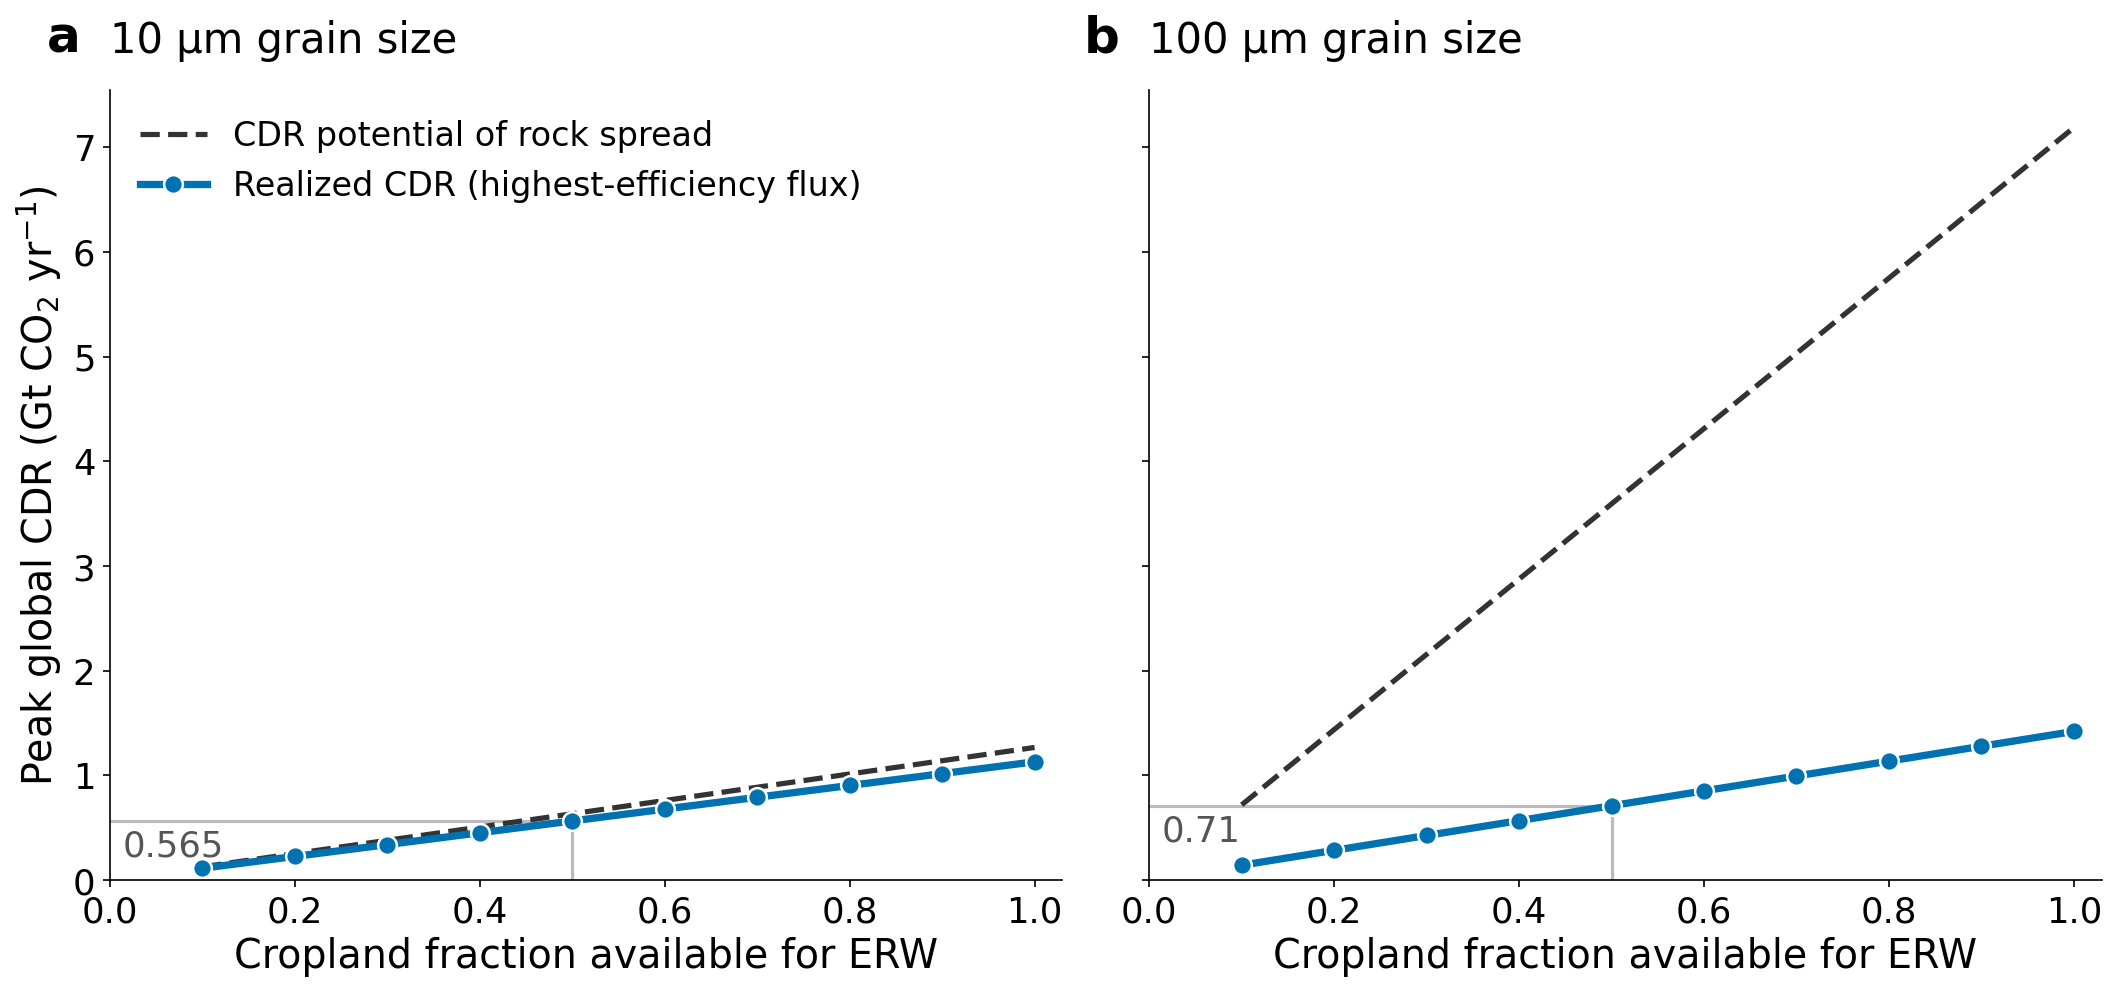

In [8]:
plot_sweep(glob.max("time"), "Peak global CDR (Gt CO$_2$ yr$^{-1}$)",
           "steady-state-cropfrac-peak.png")

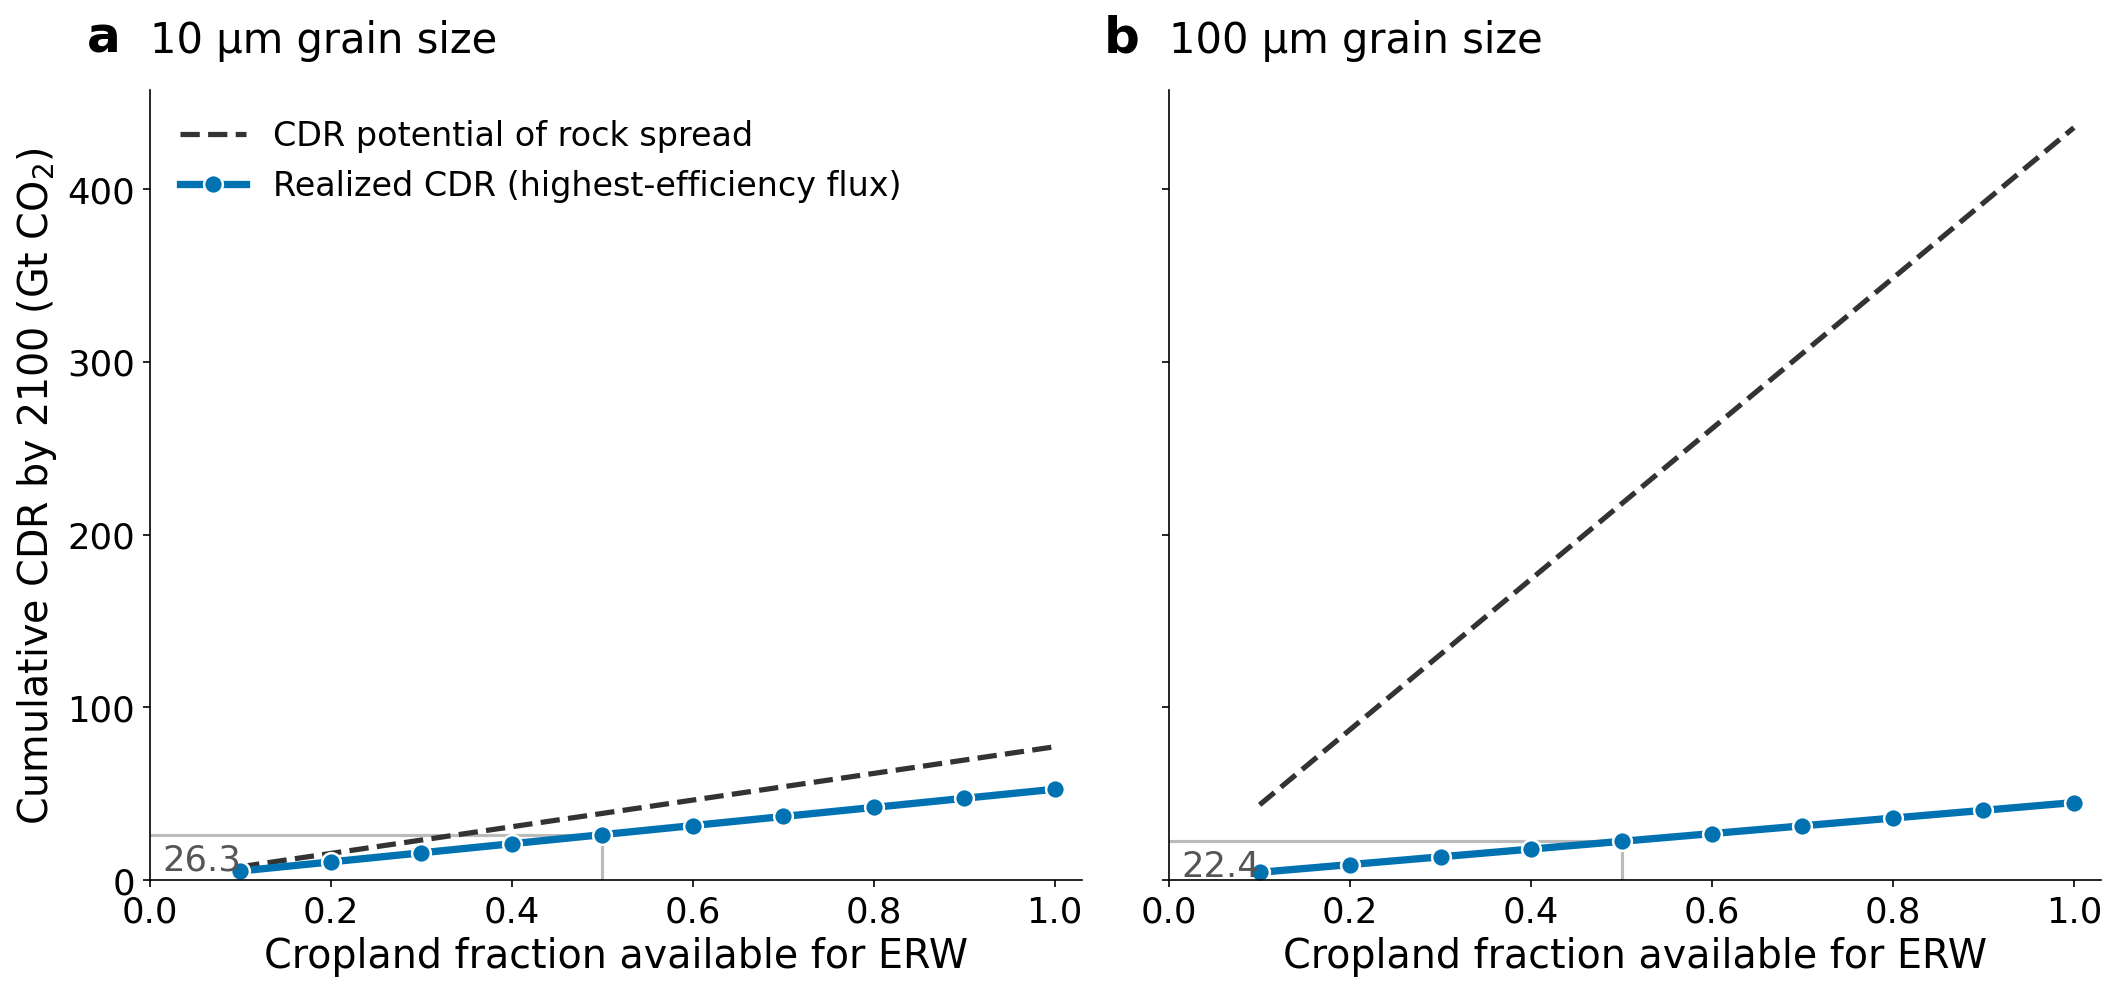

In [9]:
plot_sweep(glob.sum("time"), "Cumulative CDR by 2100 (Gt CO$_2$)",
           "steady-state-cropfrac-cum.png")

In [ ]:
# ---